# TikTok Video Performance & Engagement Analysis

**Author:** Amidu Kofi Jumah

**Project Context:** Google Data Analytics Professional Certificate

## Project Overview

This project analyzes TikTok video data to identify patterns associated with video performance and audience engagement. The analysis explores video views, engagement metrics, content type, and video duration to uncover meaningful trends and actionable insights.

## Project Objectives

- Explore and understand the structure and quality of the TikTok dataset.
- Identify characteristics associated with high-performing videos.
- Compare engagement using normalized rates rather than raw counts alone.
- Examine differences between claim and opinion videos.
- Apply statistical hypothesis testing to evaluate observed differences.
- Translate analytical findings into practical insights and recommendations.

## Tools & Technologies

**Python | Pandas | NumPy | Matplotlib | Seaborn | SciPy | Jupyter Notebook | Statistical analysis**

## Step 1: Import Libraries

The following libraries will be used for data manipulation, visualization, and analysis throughout the project.

In [80]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ttest_ind, f_oneway
pd.set_option('display.max_columns', None)

## Step 2: Load the Dataset

Load the TikTok dataset and preview the data.

In [82]:


df = pd.read_csv("tiktok_dataset.csv")

df.head()


FileNotFoundError: [Errno 2] No such file or directory: 'tiktok_dataset.csv'

## Step 3: Inspect the Dataset

Review the dataset's dimensions, data types, and summary statistics.

In [4]:
# Number of rows and columns

df.shape

(19382, 12)

In [5]:
# View column names, data types, and missing values

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 19382 entries, 0 to 19381
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   #                         19382 non-null  int64  
 1   claim_status              19084 non-null  str    
 2   video_id                  19382 non-null  int64  
 3   video_duration_sec        19382 non-null  int64  
 4   video_transcription_text  19084 non-null  str    
 5   verified_status           19382 non-null  str    
 6   author_ban_status         19382 non-null  str    
 7   video_view_count          19084 non-null  float64
 8   video_like_count          19084 non-null  float64
 9   video_share_count         19084 non-null  float64
 10  video_download_count      19084 non-null  float64
 11  video_comment_count       19084 non-null  float64
dtypes: float64(5), int64(3), str(4)
memory usage: 1.8 MB


In [6]:
# Statistical summary of numeric columns

df.describe()

,#,video_id,video_duration_sec,video_view_count,video_like_count,video_share_count,video_download_count,video_comment_count
count,19382.000000,1.938200e+04,19382.000000,19084.000000,19084.000000,19084.000000,19084.000000,19084.000000
mean,9691.500000,5.627454e+09,32.421732,254708.558688,84304.636030,16735.248323,1049.429627,349.312146
std,5595.245794,2.536440e+09,16.229967,322893.280814,133420.546814,32036.174350,2004.299894,799.638865
min,1.000000,1.234959e+09,5.000000,20.000000,0.000000,0.000000,0.000000,0.000000
25%,4846.250000,3.430417e+09,18.000000,4942.500000,810.750000,115.000000,7.000000,1.000000
50%,9691.500000,5.618664e+09,32.000000,9954.500000,3403.500000,717.000000,46.000000,9.000000
75%,14536.750000,7.843960e+09,47.000000,504327.000000,125020.000000,18222.000000,1156.250000,292.000000
max,19382.000000,9.999873e+09,60.000000,999817.000000,657830.000000,256130.000000,14994.000000,9599.000000


In [7]:
# Count missing values in each column

df.isnull().sum()

#                             0
claim_status                298
video_id                      0
video_duration_sec            0
video_transcription_text    298
verified_status               0
author_ban_status             0
video_view_count            298
video_like_count            298
video_share_count           298
video_download_count        298
video_comment_count         298
dtype: int64

In [9]:
# Check for duplicate rows
df.duplicated().sum()

np.int64(0)

## Step 4: Data Cleaning

The dataset is checked for duplicate and missing records. Rows containing missing values are removed to create a complete dataset for subsequent analysis.

In [10]:
# Create a cleaned copy of the dataset
df_clean = df.dropna()

In [11]:
# Verify that missing values have been removed
df_clean.isnull().sum()

#                           0
claim_status                0
video_id                    0
video_duration_sec          0
video_transcription_text    0
verified_status             0
author_ban_status           0
video_view_count            0
video_like_count            0
video_share_count           0
video_download_count        0
video_comment_count         0
dtype: int64

In [12]:
# Verify duplicate rows
df_clean.duplicated().sum()

np.int64(0)

In [13]:
# Confirm the dataset information after cleaning
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 19084 entries, 0 to 19083
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   #                         19084 non-null  int64  
 1   claim_status              19084 non-null  str    
 2   video_id                  19084 non-null  int64  
 3   video_duration_sec        19084 non-null  int64  
 4   video_transcription_text  19084 non-null  str    
 5   verified_status           19084 non-null  str    
 6   author_ban_status         19084 non-null  str    
 7   video_view_count          19084 non-null  float64
 8   video_like_count          19084 non-null  float64
 9   video_share_count         19084 non-null  float64
 10  video_download_count      19084 non-null  float64
 11  video_comment_count       19084 non-null  float64
dtypes: float64(5), int64(3), str(4)
memory usage: 1.7 MB


## Step 5: Exploratory Data Analysis (EDA)

### 5.1 Summary Statistics

In [14]:
# Summary statistics
df_clean.describe()

,#,video_id,video_duration_sec,video_view_count,video_like_count,video_share_count,video_download_count,video_comment_count
count,19084.000000,1.908400e+04,19084.000000,19084.000000,19084.000000,19084.000000,19084.000000,19084.000000
mean,9542.500000,5.624840e+09,32.423811,254708.558688,84304.636030,16735.248323,1049.429627,349.312146
std,5509.220604,2.537030e+09,16.226470,322893.280814,133420.546814,32036.174350,2004.299894,799.638865
min,1.000000,1.234959e+09,5.000000,20.000000,0.000000,0.000000,0.000000,0.000000
25%,4771.750000,3.425100e+09,18.000000,4942.500000,810.750000,115.000000,7.000000,1.000000
50%,9542.500000,5.609500e+09,32.000000,9954.500000,3403.500000,717.000000,46.000000,9.000000
75%,14313.250000,7.840823e+09,47.000000,504327.000000,125020.000000,18222.000000,1156.250000,292.000000
max,19084.000000,9.999873e+09,60.000000,999817.000000,657830.000000,256130.000000,14994.000000,9599.000000


### 5.2 Claim Status Distribution

In [15]:
df_clean["claim_status"].value_counts()

claim_status
claim      9608
opinion    9476
Name: count, dtype: int64

Visualization

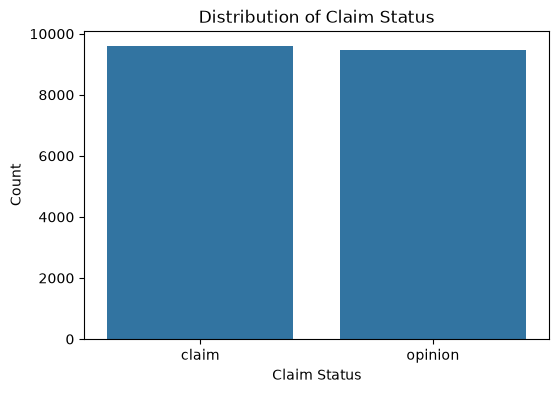

In [16]:
plt.figure(figsize=(6,4))

sns.countplot(data=df_clean, x="claim_status")

plt.title("Distribution of Claim Status")
plt.xlabel("Claim Status")
plt.ylabel("Count")

plt.show()

### 5.3 Verified Status Distribution

In [17]:
df_clean["verified_status"].value_counts()

verified_status
not verified    17884
verified         1200
Name: count, dtype: int64

#### Visualization

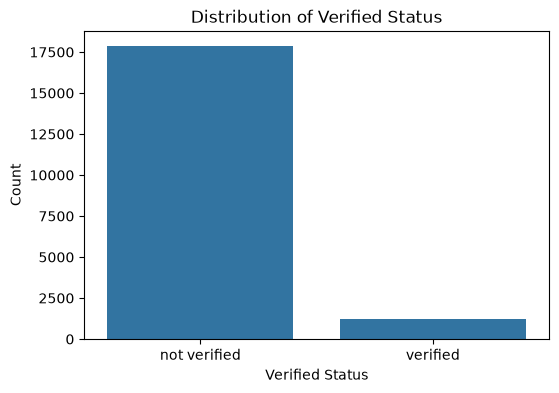

In [18]:
plt.figure(figsize=(6,4))

sns.countplot(data=df_clean, x="verified_status")

plt.title("Distribution of Verified Status")
plt.xlabel("Verified Status")
plt.ylabel("Count")

plt.show()

4. Author Ban Status

In [19]:
df_clean["author_ban_status"].value_counts()

author_ban_status
active          15383
under review     2066
banned           1635
Name: count, dtype: int64

### 5.4 Author Ban Status Distribution

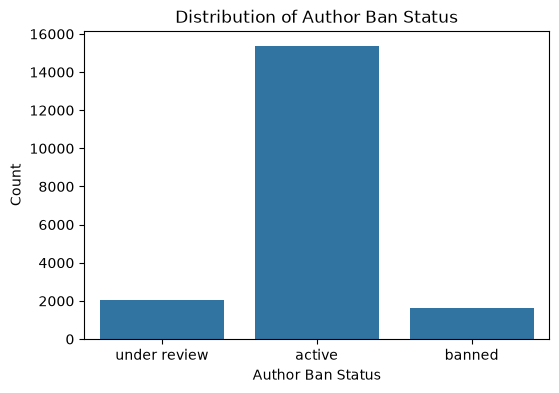

In [20]:
plt.figure(figsize=(6,4))

sns.countplot(data=df_clean, x="author_ban_status")

plt.title("Distribution of Author Ban Status")
plt.xlabel("Author Ban Status")
plt.ylabel("Count")

plt.show()

### 5.4 Author Ban Status Distribution

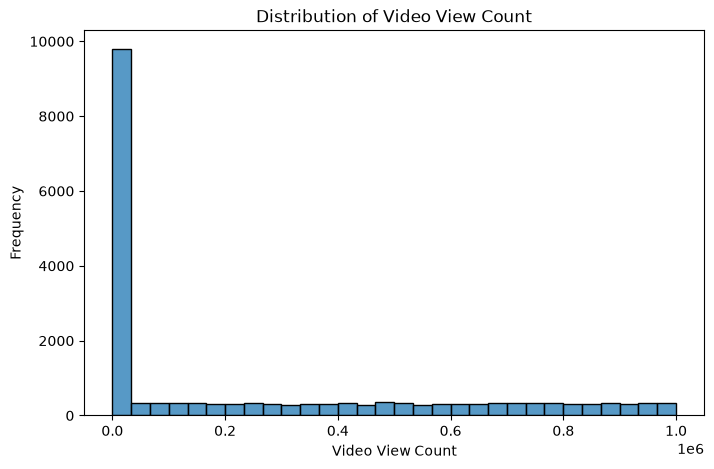

In [21]:
plt.figure(figsize=(8,5))

sns.histplot(
    df_clean["video_view_count"],
    bins=30
)

plt.title("Distribution of Video View Count")
plt.xlabel("Video View Count")
plt.ylabel("Frequency")

plt.show()

### 5.6 Average Video Views

In [22]:
df_clean["video_view_count"].mean()

np.float64(254708.5586879061)

7: Highest Video View

8: Lowest Video View

In [24]:
df_clean["video_view_count"].min()

np.float64(20.0)

## Step 6: Comparative Analysis

### 6.1 Video Views by Verification Status

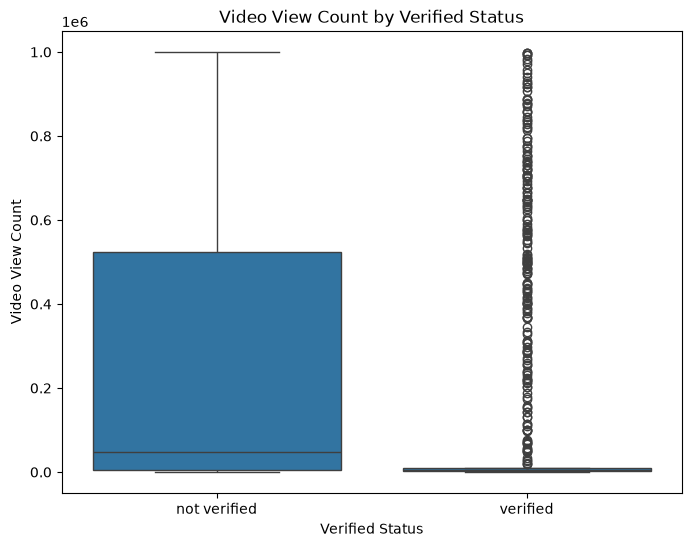

In [25]:
plt.figure(figsize=(8,6))

sns.boxplot(
    data=df_clean,
    x="verified_status",
    y="video_view_count"
)

plt.title("Video View Count by Verified Status")
plt.xlabel("Verified Status")
plt.ylabel("Video View Count")

plt.show()

### Insight: Video Views by Verification Status

The distribution of video views differs noticeably between verified and non-verified accounts. Non-verified accounts show a higher median and a wider typical range of video views.

Verified accounts have a much lower typical view count, but they also contain numerous high-view outliers, indicating that some verified accounts still achieve very high video reach.

This suggests that verification status alone does not consistently indicate higher video performance.

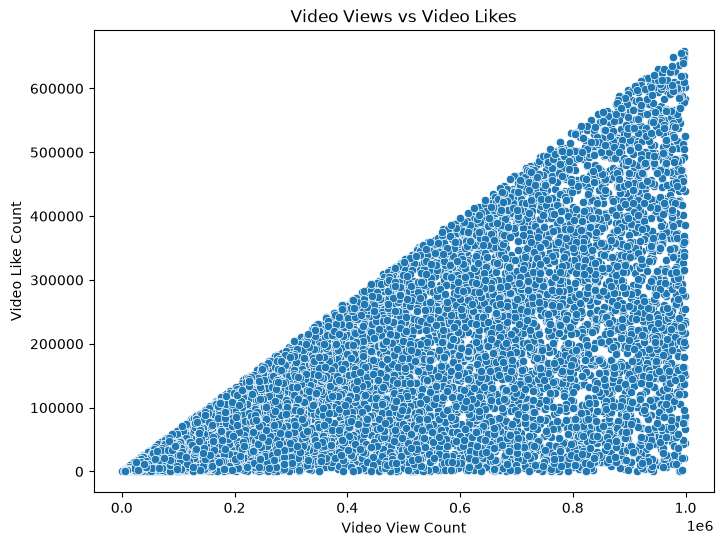

In [61]:
plt.figure(figsize=(8,6))

sns.scatterplot(
    data=df_clean,
    x="video_view_count",
    y="video_like_count"
)

plt.title("Video Views vs Video Likes")
plt.xlabel("Video View Count")
plt.ylabel("Video Like Count")

plt.show()

In [27]:
# Calculate correlation between views and likes
correlation = df_clean["video_view_count"].corr(df_clean["video_like_count"])

print("Correlation:", correlation)

Correlation: 0.8043221351779141


### Insight: Relationship Between Video Views and Likes

Video views and likes have a strong positive correlation (r = 0.804). This indicates that videos with higher view counts generally tend to receive more likes.

The scatterplot also shows that the variation in likes becomes wider as view counts increase, meaning videos with similar numbers of views can receive substantially different numbers of likes.

This relationship represents an association and should not be interpreted as evidence of causation.

In [28]:
# Select only numerical columns
numeric_df = df_clean.select_dtypes(include=["number"])

# Display the correlation matrix
numeric_df.corr()

,#,video_id,video_duration_sec,video_view_count,video_like_count,video_share_count,video_download_count,video_comment_count
#,1.000000,-0.003590,-0.000145,-0.668047,-0.540852,-0.451713,-0.447729,-0.377445
video_id,-0.003590,1.000000,0.008460,0.000217,0.000236,-0.002721,0.002155,0.005336
video_duration_sec,-0.000145,0.008460,1.000000,0.008481,0.011567,0.011560,0.013078,0.000615
video_view_count,-0.668047,0.000217,0.008481,1.000000,0.804322,0.665635,0.664222,0.554172
video_like_count,-0.540852,0.000236,0.011567,0.804322,1.000000,0.825789,0.823554,0.687185
video_share_count,-0.451713,-0.002721,0.011560,0.665635,0.825789,1.000000,0.679910,0.574632
video_download_count,-0.447729,0.002155,0.013078,0.664222,0.823554,0.679910,1.000000,0.832464
video_comment_count,-0.377445,0.005336,0.000615,0.554172,0.687185,0.574632,0.832464,1.000000


### 6.3 Correlation Analysis of Numerical Variables

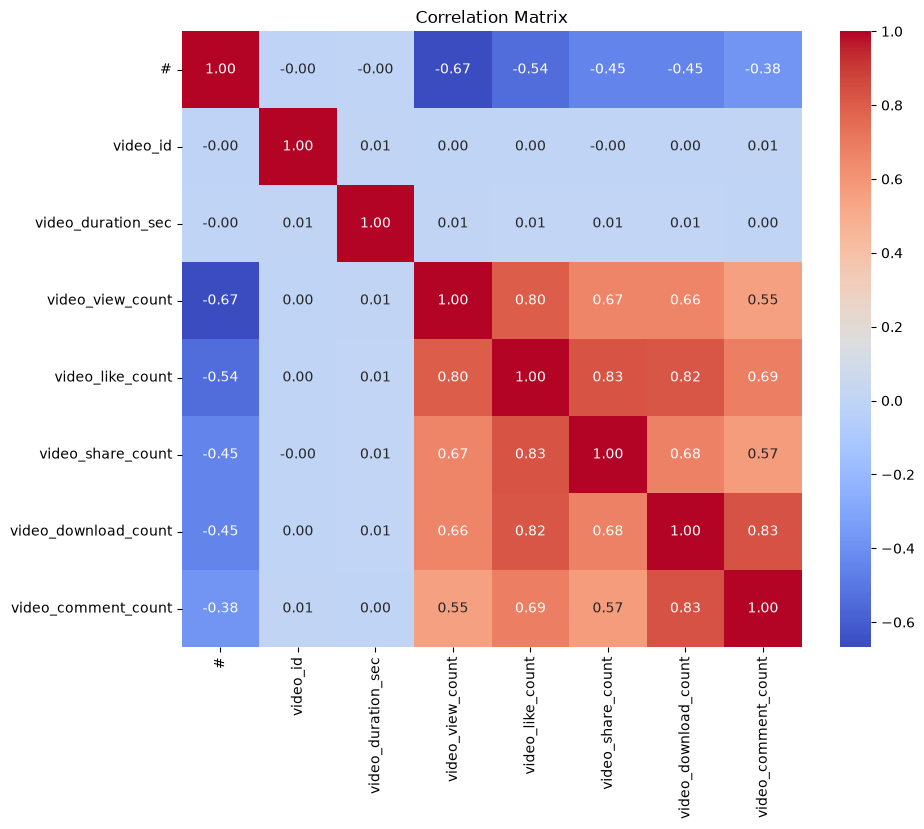

In [62]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")

plt.show()

## Correlation Analysis: Key Insights

The correlation heatmap reveals several notable relationships among TikTok engagement metrics.

- **Video downloads and comments (r = 0.83)** show a strong positive correlation, indicating that videos with higher download activity also tend to receive more comments.
- **Video downloads and likes (r = 0.82)** also demonstrate a strong positive relationship, suggesting that highly liked content is often downloaded more frequently.
- **Video views and downloads (r = 0.66)** show a moderate-to-strong positive relationship, indicating that videos with greater reach tend to generate more downloads.

Overall, the analysis suggests that TikTok engagement behaviors—including likes, comments, downloads, and views—are interconnected. However, these correlations indicate associations rather than causal relationships.

In [30]:
df['video_view_count'].describe()

count     19084.000000
mean     254708.558688
std      322893.280814
min          20.000000
25%        4942.500000
50%        9954.500000
75%      504327.000000
max      999817.000000
Name: video_view_count, dtype: float64

In [31]:
high_view_threshold = df['video_view_count'].quantile(0.75)

df['performance_group'] = np.where(
    df['video_view_count'] >= high_view_threshold,
    'High-performing',
    'Other'
)

df['performance_group'].value_counts()

performance_group
Other              14611
High-performing     4771
Name: count, dtype: int64

In [32]:
engagement_comparison = df.groupby('performance_group')[
    [
        'video_like_count',
        'video_share_count',
        'video_download_count',
        'video_comment_count'
    ]
].mean().round(2)

engagement_comparison

,video_like_count,video_share_count,video_download_count,video_comment_count
performance_group,,,,
High-performing,249778.35,49344.31,3099.32,1035.05
Other,29146.73,5865.56,366.13,120.73


In [33]:
engagement_ratio = (
    engagement_comparison.loc['High-performing'] /
    engagement_comparison.loc['Other']
).round(2)

engagement_ratio

video_like_count        8.57
video_share_count       8.41
video_download_count    8.47
video_comment_count     8.57
dtype: float64

## High-Performing Video Analysis

Videos in the top 25% of the `video_view_count` distribution were classified as **high-performing**, using the 75th percentile (504,327 views) as the threshold.

Compared with other videos, high-performing videos generated substantially greater average engagement:

- **8.57× more likes**
- **8.41× more shares**
- **8.47× more downloads**
- **8.57× more comments**

These results show that high-view TikTok videos are strongly associated with higher engagement across multiple audience behaviors. However, because performance groups were defined using view counts, these comparisons should be interpreted as **associations rather than evidence that engagement causes higher reach**.

In [34]:
df['like_rate'] = df['video_like_count'] / df['video_view_count']
df['share_rate'] = df['video_share_count'] / df['video_view_count']
df['comment_rate'] = df['video_comment_count'] / df['video_view_count']
df['download_rate'] = df['video_download_count'] / df['video_view_count']

rate_comparison = df.groupby('performance_group')[
    ['like_rate', 'share_rate', 'comment_rate', 'download_rate']
].mean().mul(100).round(2)

rate_comparison

,like_rate,share_rate,comment_rate,download_rate
performance_group,,,,
High-performing,33.04,6.51,0.14,0.41
Other,25.80,5.15,0.08,0.32


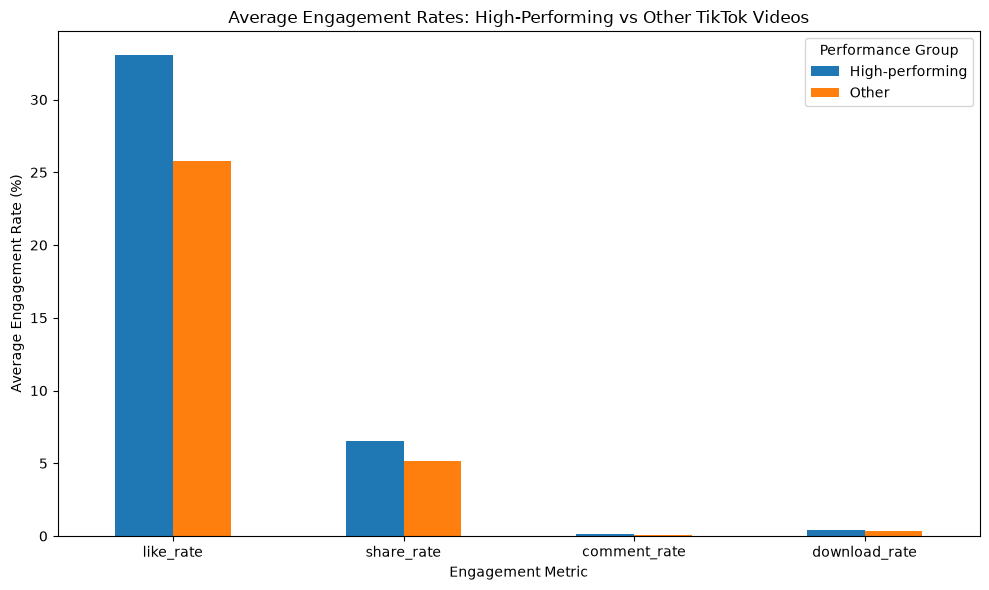

In [35]:
rate_plot = rate_comparison.T

rate_plot.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Average Engagement Rates: High-Performing vs Other TikTok Videos')
plt.xlabel('Engagement Metric')
plt.ylabel('Average Engagement Rate (%)')
plt.xticks(rotation=0)
plt.legend(title='Performance Group')
plt.tight_layout()
plt.show()

In [36]:
rate_lift = (
    rate_comparison.loc['High-performing'] /
    rate_comparison.loc['Other']
)

rate_lift

like_rate        1.280620
share_rate       1.264078
comment_rate     1.750000
download_rate    1.281250
dtype: float64

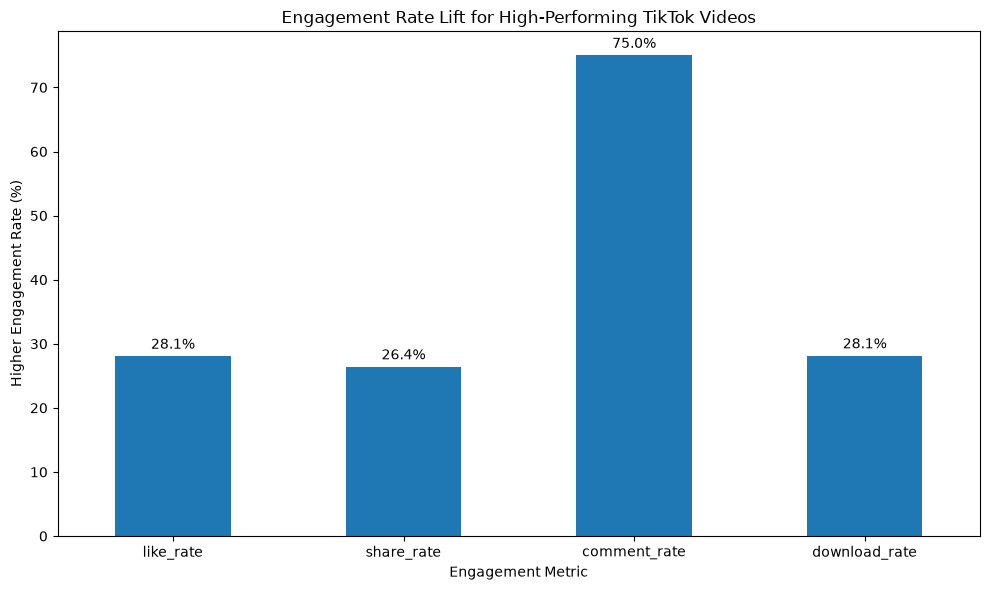

In [37]:
rate_lift_percent = (rate_lift - 1) * 100

ax = rate_lift_percent.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Engagement Rate Lift for High-Performing TikTok Videos')
plt.xlabel('Engagement Metric')
plt.ylabel('Higher Engagement Rate (%)')
plt.xticks(rotation=0)

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3)

plt.tight_layout()
plt.show()

### Engagement Rate Insight

After normalizing engagement by video views, high-performing videos continued to show stronger audience interaction than other videos.

- **Comment rate was approximately 75% higher**, representing the largest relative difference.
- **Like rate was approximately 28.1% higher.**
- **Download rate was approximately 28.1% higher.**
- **Share rate was approximately 26.4% higher.**

This suggests that the difference between high-performing and other videos is not explained solely by greater reach. High-performing videos are also associated with stronger engagement relative to their view counts, with commenting showing the largest relative difference.

These findings describe associations in the dataset and should not be interpreted as evidence that higher engagement rates cause videos to receive more views.

In [38]:
df.groupby('performance_group')['video_duration_sec'].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
performance_group,,,,,,,,
High-performing,4771.0,32.69,16.27,5.0,19.0,33.0,47.0,60.0
Other,14611.0,32.33,16.22,5.0,18.0,32.0,46.0,60.0


### Video Duration and Performance

Video duration was very similar across performance groups.

- High-performing videos had an average duration of **32.69 seconds** and a median duration of **33 seconds**.
- Other videos had an average duration of **32.33 seconds** and a median duration of **32 seconds**.
- The middle 50% of high-performing videos ranged from **19 to 47 seconds**, compared with **18 to 46 seconds** for other videos.

Based on these descriptive statistics, video duration does not appear to meaningfully distinguish high-performing videos from other videos in this dataset. This suggests that higher view performance is associated more strongly with other characteristics than with video length alone.

In [40]:
df['claim_status'].value_counts(dropna=False)

claim_status
claim      9608
opinion    9476
NaN         298
Name: count, dtype: int64

In [41]:
claim_performance = pd.crosstab(
    df['claim_status'],
    df['performance_group'],
    normalize='index'
).mul(100).round(2)

claim_performance

performance_group,High-performing,Other
claim_status,,
claim,49.66,50.34
opinion,0.00,100.00


In [42]:
df.groupby('claim_status')['video_view_count'].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
claim_status,,,,,,,,
claim,9608.0,501029.45,291349.24,1049.0,247003.75,501555.0,753088.00,999817.0
opinion,9476.0,4956.43,2885.91,20.0,2467.00,4953.0,7447.25,9998.0


In [43]:
claim_rate_comparison = df.groupby('claim_status')[
    ['like_rate', 'share_rate', 'comment_rate', 'download_rate']
].mean().mul(100).round(2)

claim_rate_comparison

,like_rate,share_rate,comment_rate,download_rate
claim_status,,,,
claim,33.16,6.59,0.14,0.41
opinion,21.98,4.37,0.05,0.27


In [44]:
claim_rate_lift = (
    claim_rate_comparison.loc['claim'] /
    claim_rate_comparison.loc['opinion'] - 1
).mul(100).round(1)

claim_rate_lift

like_rate         50.9
share_rate        50.8
comment_rate     180.0
download_rate     51.9
dtype: float64

### Claim Status and Engagement

Claim videos substantially outperformed opinion videos in both reach and normalized engagement.

- Claim videos averaged approximately **501,029 views**, compared with **4,956 views** for opinion videos.
- Claim videos had a **50.9% higher like rate**.
- Claim videos had a **50.8% higher share rate**.
- Claim videos had a **51.9% higher download rate**.
- The largest difference was in commenting: claim videos had an approximately **180% higher comment rate** than opinion videos.

These findings suggest that claim-based content is strongly associated with both greater reach and stronger audience engagement in this dataset. In particular, the substantially higher relative comment rate suggests that claim videos are associated with greater audience discussion and interaction.

However, these results represent associations within the dataset and should not be interpreted as evidence that publishing claim-based content directly causes higher engagement or viewership.

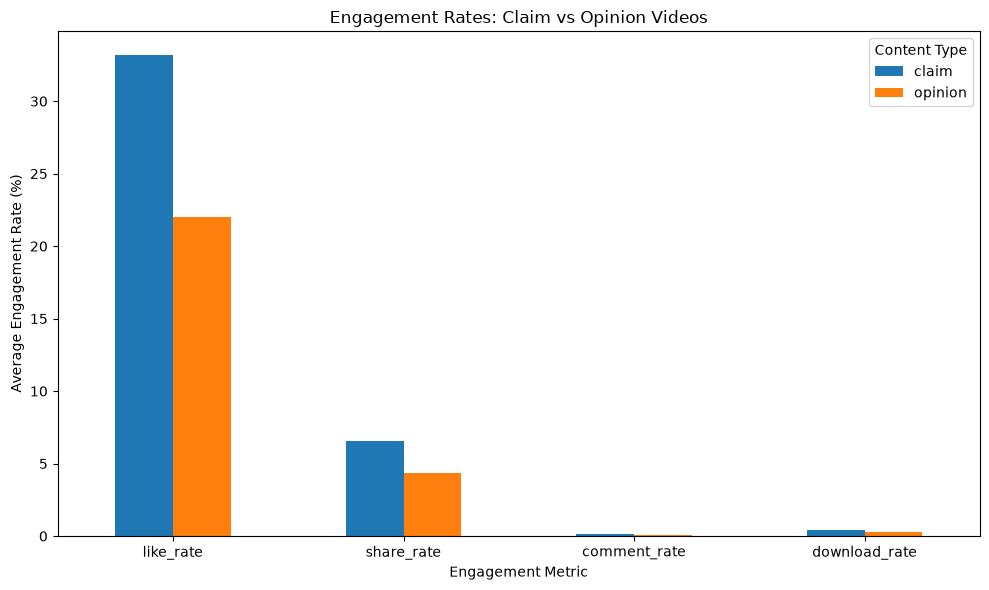

In [45]:
claim_rate_comparison.T.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Engagement Rates: Claim vs Opinion Videos')
plt.xlabel('Engagement Metric')
plt.ylabel('Average Engagement Rate (%)')
plt.xticks(rotation=0)
plt.legend(title='Content Type')
plt.tight_layout()
plt.show()

In [63]:
from scipy.stats import ttest_ind

# Separate the two groups
claim_views = df[df['claim_status'] == 'claim']['video_view_count'].dropna()
opinion_views = df[df['claim_status'] == 'opinion']['video_view_count'].dropna()

# Welch's independent samples t-test
t_stat, p_value = ttest_ind(
    claim_views,
    opinion_views,
    equal_var=False
)

print("T-statistic:", t_stat)
print("P-value:", p_value)

T-statistic: 166.88857822856752
P-value: 0.0


## Hypothesis Testing: Claim vs Opinion Video Views

A Welch's independent samples t-test was conducted to determine whether the average number of views differed significantly between claim and opinion videos.

**Hypotheses:**

- **H₀ (Null Hypothesis):** There is no significant difference in average video views between claim and opinion videos.
- **H₁ (Alternative Hypothesis):** There is a significant difference in average video views between claim and opinion videos.

Using a significance level of **α = 0.05**, the test produced:

- **T-statistic:** 166.89
- **P-value:** < 0.05

Because the p-value is below 0.05, the null hypothesis is rejected. This provides strong statistical evidence that average video views differ between claim and opinion videos.

Claim videos averaged approximately **501,029 views**, compared with approximately **4,956 views** for opinion videos.

### Conclusion

Claim videos are associated with significantly higher average view counts than opinion videos in this dataset. However, statistical significance does not establish causation. Other factors may influence video performance, so these results should not be interpreted as evidence that creating claim-based content directly causes higher views.

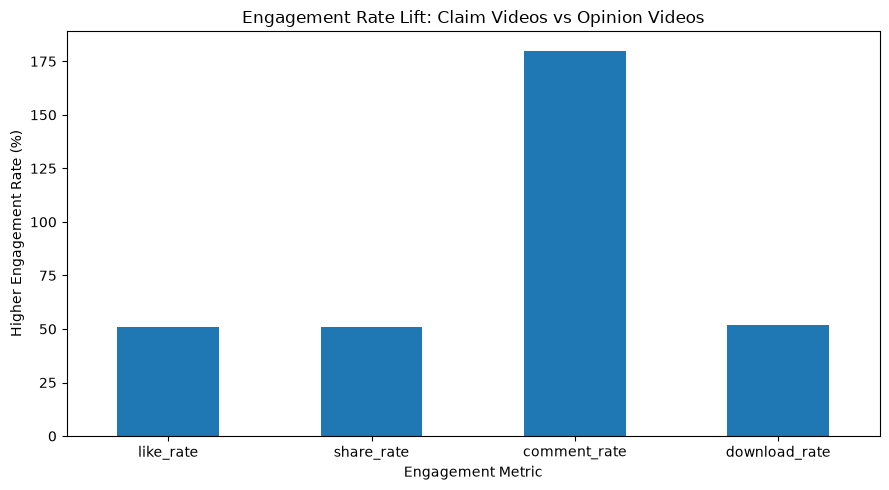

In [46]:
claim_rate_lift.plot(
    kind='bar',
    figsize=(9, 5)
)

plt.title('Engagement Rate Lift: Claim Videos vs Opinion Videos')
plt.xlabel('Engagement Metric')
plt.ylabel('Higher Engagement Rate (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [66]:
df['verified_status'].value_counts(dropna=False)

verified_status
not verified    18142
verified         1240
Name: count, dtype: int64

In [67]:
df.groupby('verified_status')['video_view_count'].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
verified_status,,,,,,,,
not verified,17884.0,265663.79,325681.88,20.0,5160.00,46723.0,523099.50,999817.0
verified,1200.0,91439.16,221138.76,37.0,2974.75,6023.5,9036.75,997769.0


In [68]:
verified_views = df[df['verified_status'] == 'verified']['video_view_count'].dropna()

not_verified_views = df[df['verified_status'] == 'not verified']['video_view_count'].dropna()

t_stat, p_value = ttest_ind(
    verified_views,
    not_verified_views,
    equal_var=False
)

print("T-statistic:", t_stat)
print("P-value:", p_value)

T-statistic: -25.499441780633777
P-value: 2.6088823687177503e-120


In [50]:
from scipy.stats import ttest_ind

claim_views = df[df['claim_status'] == 'claim']['video_view_count'].dropna()
opinion_views = df[df['claim_status'] == 'opinion']['video_view_count'].dropna()

t_stat, p_value = ttest_ind(
    claim_views,
    opinion_views,
    equal_var=False
)

print("T-statistic:", t_stat)
print("P-value:", p_value)

T-statistic: 166.88857822856752
P-value: 0.0


In [48]:
%pip install scipy

   ---------------------------------------- 0.0/36.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/36.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/36.6 MB ? eta -:--:--
   ---------------------------------------- 0.3/36.6 MB ? eta -:--:--
    --------------------------------------- 0.5/36.6 MB 668.9 kB/s eta 0:00:54
    --------------------------------------- 0.5/36.6 MB 668.9 kB/s eta 0:00:54
    --------------------------------------- 0.8/36.6 MB 668.2 kB/s eta 0:00:54
    --------------------------------------- 0.8/36.6 MB 668.2 kB/s eta 0:00:54
   - -------------------------------------- 1.0/36.6 MB 697.3 kB/s eta 0:00:52
   - -------------------------------------- 1.3/36.6 MB 710.9 kB/s eta 0:00:50
   - -------------------------------------- 1.3/36.6 MB 710.9 kB/s eta 0:00:50
   - -------------------------------------- 1.6/36.6 MB 728.6 kB/s eta 0:00:49
   -- ------------------------------------- 1.8/36.6 MB 739.9 kB/s eta 0:00:48
   -- ---


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: C:\Users\hp\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


In [74]:
verification_rate_comparison = df.groupby('verified_status')[
    ['like_rate', 'share_rate', 'comment_rate', 'download_rate']
].mean().mul(100).round(2)

verification_rate_comparison

,like_rate,share_rate,comment_rate,download_rate
verified_status,,,,
not verified,27.85,5.53,0.10,0.35
verified,24.02,4.82,0.07,0.29


In [71]:
df.columns.tolist()

['#',
 'claim_status',
 'video_id',
 'video_duration_sec',
 'video_transcription_text',
 'verified_status',
 'author_ban_status',
 'video_view_count',
 'video_like_count',
 'video_share_count',
 'video_download_count',
 'video_comment_count']

In [72]:
df['like_rate'] = df['video_like_count'] / df['video_view_count']
df['share_rate'] = df['video_share_count'] / df['video_view_count']
df['comment_rate'] = df['video_comment_count'] / df['video_view_count']
df['download_rate'] = df['video_download_count'] / df['video_view_count']

In [73]:
df[['like_rate', 'share_rate', 'comment_rate', 'download_rate']].head()

,like_rate,share_rate,comment_rate,download_rate
0,0.056584,0.000702,0.000000,0.000003
1,0.549096,0.135111,0.004855,0.008241
2,0.108282,0.003168,0.000365,0.000923
3,0.548459,0.079569,0.001335,0.002821
4,0.622910,0.073175,0.002706,0.009739


In [53]:
t_stat, p_value = ttest_ind(
    claim_comments,
    opinion_comments,
    equal_var=False
)

print("T-statistic:", t_stat)
print("P-value:", p_value)

T-statistic: 48.21030399045547
P-value: 0.0


claim_comments = df[df['claim_status'] == 'claim']['comment_rate'].dropna()

opinion_comments = df[df['claim_status'] == 'opinion']['comment_rate'].dropna()

### Hypothesis Testing: Claim vs. Opinion Videos

A Welch's independent-samples t-test was conducted to determine whether
engagement differed significantly between claim and opinion videos.

For comment rate, the test produced a t-statistic of approximately 48.21
with an extremely small p-value (p < 0.05). Therefore, the null hypothesis
was rejected.

This provides strong statistical evidence that the average comment rate
differs between claim and opinion videos. Earlier descriptive analysis showed
that claim videos had the higher average comment rate.

However, these results demonstrate an association rather than causation,
because the analysis is based on observational data.

In [75]:
df['author_ban_status'].value_counts(dropna=False)

author_ban_status
active          15663
under review     2080
banned           1639
Name: count, dtype: int64

In [76]:
df.groupby('author_ban_status')['video_view_count'].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
author_ban_status,,,,,,,,
active,15383.0,215927.04,310342.34,20.0,4301.50,8616.0,412150.50,999817.0
banned,1635.0,445845.44,314928.25,72.0,153661.50,448201.0,722869.00,997703.0
under review,2066.0,392204.84,329451.82,75.0,37035.75,365245.5,684012.25,999655.0


In [77]:
ban_engagement = df.groupby('author_ban_status')[
    ['like_rate', 'share_rate', 'comment_rate', 'download_rate']
].mean().mul(100).round(2)

ban_engagement

,like_rate,share_rate,comment_rate,download_rate
author_ban_status,,,,
active,26.66,5.30,0.09,0.33
banned,32.85,6.46,0.13,0.40
under review,30.52,6.10,0.12,0.38


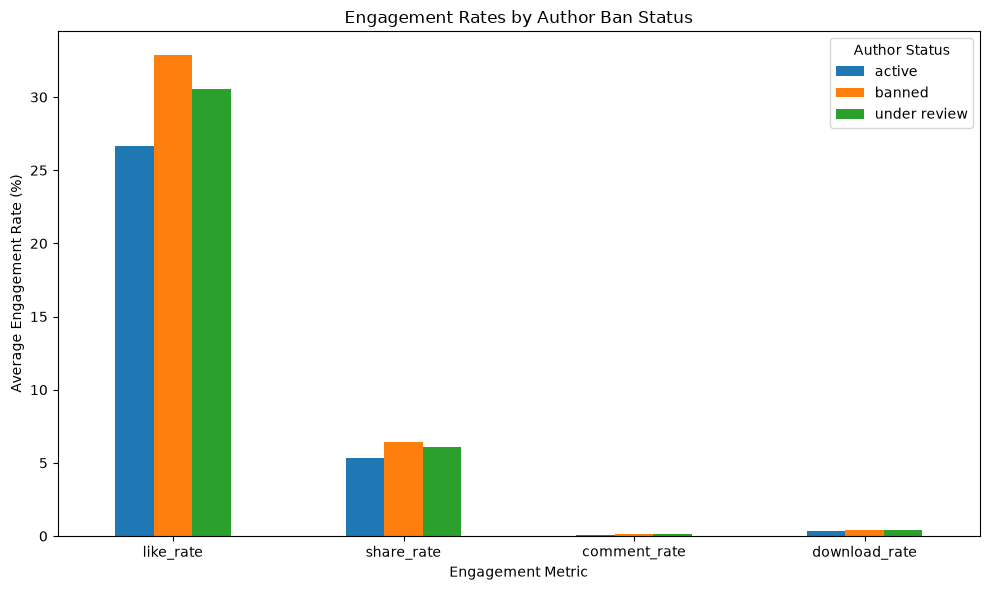

In [78]:
ban_engagement.T.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Engagement Rates by Author Ban Status')
plt.xlabel('Engagement Metric')
plt.ylabel('Average Engagement Rate (%)')
plt.xticks(rotation=0)
plt.legend(title='Author Status')
plt.tight_layout()
plt.show()

In [79]:
from scipy.stats import f_oneway

active_comments = df[
    df['author_ban_status'] == 'active'
]['comment_rate'].dropna()

banned_comments = df[
    df['author_ban_status'] == 'banned'
]['comment_rate'].dropna()

review_comments = df[
    df['author_ban_status'] == 'under review'
]['comment_rate'].dropna()

f_stat, p_value = f_oneway(
    active_comments,
    banned_comments,
    review_comments
)

print("F-statistic:", f_stat)
print("P-value:", p_value)

F-statistic: 93.36479698109932
P-value: 4.459667332718772e-41


# TikTok Project: Key Findings

### 1. High-Performing Videos
Videos in the top 25% of view counts received approximately **504,327 views or more**.

### 2. Video Duration
Average video duration was very similar between high-performing and other videos, suggesting that video duration alone did not meaningfully distinguish performance in this dataset.

### 3. Content Type
Claim videos received substantially more views than opinion videos. Claim videos averaged approximately **501,029 views**, compared with approximately **4,956 views** for opinion videos.

### 4. Engagement
Claim videos also had higher normalized engagement rates than opinion videos:
- Like rate: approximately **50.9% higher**
- Share rate: approximately **50.8% higher**
- Comment rate: approximately **180% higher**
- Download rate: approximately **51.9% higher**

### 5. Statistical Evidence
Hypothesis testing found statistically significant differences in video performance across several groups. In particular, the difference in average views between claim and opinion videos was statistically significant (**p < 0.05**).

### Conclusion
The analysis indicates that **content type and engagement are strongly associated with video performance**, while video duration appears to have relatively little relationship with performance. Claim-based videos were associated with substantially greater reach and engagement than opinion-based videos.

These findings represent **associations rather than causal relationships**. The analysis does not establish that creating claim-based content directly causes higher views or engagement.

## Business Insights and Recommendations

Based on the exploratory and statistical analysis, several insights can be drawn from the TikTok dataset:

1. **Content type appears strongly associated with performance.**  
   Claim videos received substantially more views and achieved higher normalized engagement rates than opinion videos. Content teams may therefore investigate what characteristics of claim-based videos are associated with stronger audience response.

2. **Comments may be an important engagement signal.**  
   Claim videos showed the largest relative increase in comment rate compared with opinion videos, suggesting that this type of content may encourage more audience discussion and interaction.

3. **Video duration does not appear to be a major performance differentiator.**  
   High-performing and other videos had very similar average durations. Content strategy should therefore not rely on video length alone when attempting to improve performance.

4. **Engagement should be evaluated relative to audience reach.**  
   Normalized engagement rates provide a more meaningful comparison than raw engagement counts because videos with more views naturally have more opportunities to receive likes, comments, shares, and downloads.

### Recommendation

Future analysis should investigate additional factors that may explain why claim videos perform differently from opinion videos. The findings should not be interpreted as evidence that claim-based content directly causes higher views or engagement because the dataset is observational.